# Travel Doctor: analyzing the synthetic trip dataset

This notebook analyzes the same data the Travel Doctor dashboard shows, with Python and pandas, as a second, independent check.

**The data is synthetic:** made up but realistic, created by `scripts/make_sample_data.py` with a fixed seed, so anyone gets the same numbers. It has two tables:

* `trips.csv`: one row per trip (who, where, how many days, budget, budget split by category)
* `*_expenses.csv`: one row per expense (day, city, item, category, amount, currency, amount in USD, who paid, who it was for)

**Questions:**
1. Did each trip stay within budget, and by how much?
2. Which categories went over the plan (the "budget prescription")?
3. Which days blew the daily budget?
4. In the group trip, who owes who? Does pandas get the same answer as the app?

Run it with `jupyter notebook analysis/travel_expenses_analysis.ipynb` (needs pandas and matplotlib).

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path("../public/datasets")
trips = pd.read_csv(DATA / "trips.csv")
expenses = pd.concat([pd.read_csv(DATA / f"{t}_expenses.csv") for t in trips.trip_id], ignore_index=True)

# chart style: thin marks, quiet grid, one accent color
BLUE, INK, MUTED, GRID = "#2a78d6", "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GRID,
                     "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
                     "axes.axisbelow": True, "font.size": 10})
print(f"{len(trips)} trips, {len(expenses)} expenses")
expenses.head()

3 trips, 97 expenses


,trip_id,day,date,city,item,category,amount,currency,rate_to_usd,amount_usd,paid_by,split_between,source
0,swiss_family,1,2026-09-12,Zurich,"Hotel in Zurich, 2 nights",stays,378.0,CHF,1.13,427.14,Priya,NaN,synthetic
1,swiss_family,1,2026-09-12,Zurich,Airport train to Zurich HB,transport,44.0,CHF,1.13,49.72,Priya,NaN,synthetic
2,swiss_family,1,2026-09-12,Zurich,Breakfast,food,32.5,CHF,1.13,36.72,Priya,NaN,synthetic
3,swiss_family,1,2026-09-12,Zurich,Lunch,food,82.0,CHF,1.13,92.66,Priya,NaN,synthetic
4,swiss_family,1,2026-09-12,Zurich,Dinner,food,152.0,CHF,1.13,171.76,Priya,NaN,synthetic


## 1. Did each trip stay within budget?

In [2]:
spent = expenses.groupby("trip_id")["amount_usd"].sum().rename("spent_usd")
summary = trips.set_index("trip_id")[["trip_name", "party_type", "travelers", "days", "budget_usd"]].join(spent)
summary["left_usd"] = summary.budget_usd - summary.spent_usd
summary["pct_of_budget"] = (summary.spent_usd / summary.budget_usd * 100).round(1)
summary["per_person_per_day"] = (summary.spent_usd / summary.travelers / summary.days).round(2)
summary.round(2)

,trip_name,party_type,travelers,days,budget_usd,spent_usd,left_usd,pct_of_budget,per_person_per_day
trip_id,,,,,,,,,
swiss_family,Swiss Alps week,family,3,7,6000,5080.37,919.63,84.7,241.92
athens_group,Athens with friends,group,4,5,4800,2943.00,1857.00,61.3,147.15
lisbon_solo,Lisbon solo,solo,1,4,1400,818.64,581.36,58.5,204.66


## 2. Which categories went over the plan?

The plan for each category is the trip budget times its split percent, the same "budget prescription" the app shows.

In [3]:
cats = ["stays", "transport", "food", "experiences", "other"]
plan = trips.set_index("trip_id")[[f"split_{c}" for c in cats]].mul(trips.set_index("trip_id").budget_usd, axis=0) / 100
plan.columns = cats
actual = expenses.pivot_table(index="trip_id", columns="category", values="amount_usd", aggfunc="sum").reindex(columns=cats).fillna(0)
vs = (actual - plan).round(0)
vs  # positive = over the plan, in USD

category,stays,transport,food,experiences,other
trip_id,,,,,
athens_group,-1157.0,-567.0,52.0,-71.0,-114.0
lisbon_solo,-272.0,-102.0,-90.0,-73.0,-45.0
swiss_family,-826.0,-488.0,964.0,-354.0,-215.0


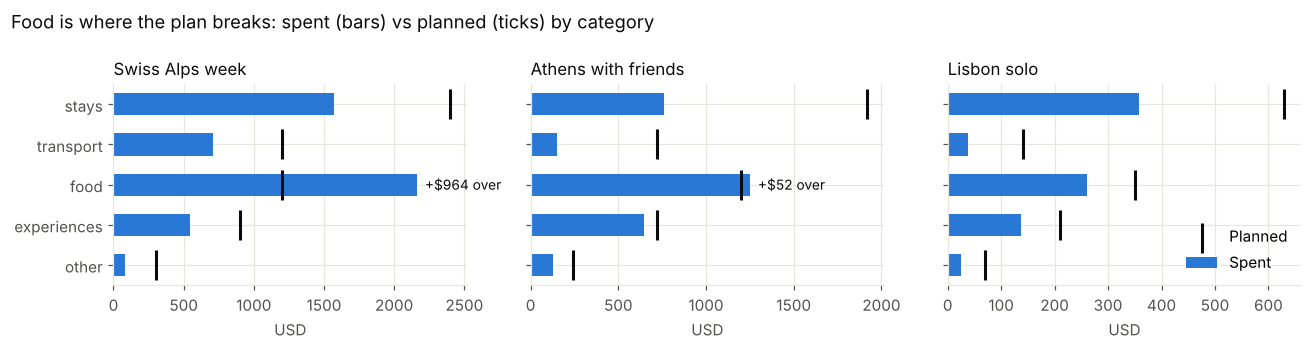

In [4]:
fig, axes = plt.subplots(1, len(trips), figsize=(12, 3.2), sharey=True)
for ax, (tid, name) in zip(axes, trips.set_index("trip_id").trip_name.items()):
    a, p = actual.loc[tid], plan.loc[tid]
    ax.barh(cats, a, color=BLUE, height=0.55, label="Spent")
    ax.scatter(p, cats, marker="|", s=400, color=INK, linewidths=2, label="Planned", zorder=3)
    for y, (c, v) in enumerate(a.items()):
        if v > p[c]:
            ax.text(v, y, f"  +${v - p[c]:,.0f} over", va="center", fontsize=9, color=INK)
    ax.set_title(name, loc="left", fontsize=11, color=INK)
    ax.set_xlabel("USD")
axes[0].invert_yaxis()
axes[-1].legend(frameon=False, loc="lower right")
fig.suptitle("Food is where the plan breaks: spent (bars) vs planned (ticks) by category", x=0.01, ha="left", fontsize=12, color=INK)
plt.tight_layout(); plt.show()

## 3. Which days blew the daily budget?

Daily budget = trip budget / number of days. Shown per person, so trips of different sizes can be compared.

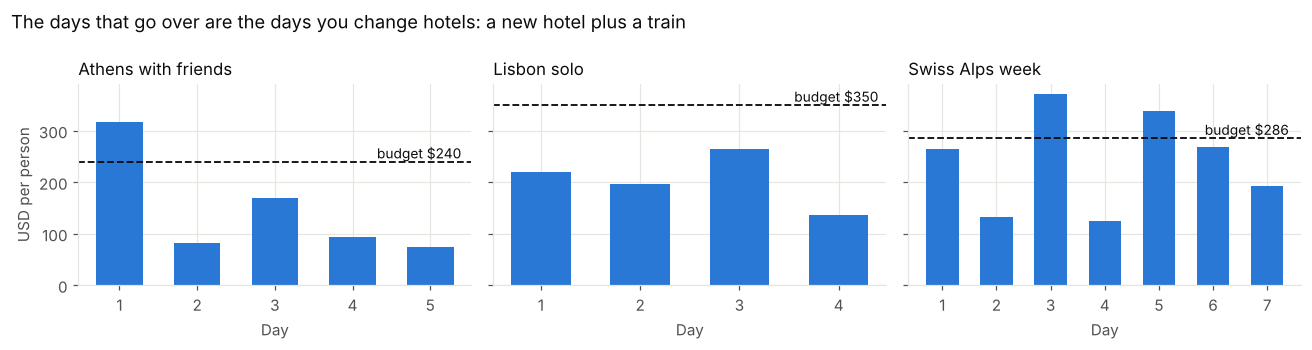

3 of 16 trip days went over the daily budget


In [5]:
daily = expenses.groupby(["trip_id", "day"])["amount_usd"].sum().reset_index()
daily = daily.merge(trips[["trip_id", "trip_name", "travelers", "days", "budget_usd"]], on="trip_id")
daily["per_person"] = daily.amount_usd / daily.travelers
daily["budget_per_person"] = daily.budget_usd / daily.days / daily.travelers

fig, axes = plt.subplots(1, len(trips), figsize=(12, 3.2), sharey=True)
for ax, (tid, g) in zip(axes, daily.groupby("trip_id", sort=False)):
    ax.bar(g.day, g.per_person, color=BLUE, width=0.6)
    b = g.budget_per_person.iloc[0]
    ax.axhline(b, color=INK, linestyle="--", linewidth=1.2)
    ax.text(g.day.max() + 0.4, b, f"budget ${b:,.0f}", va="bottom", ha="right", fontsize=9, color=INK)
    ax.set_title(g.trip_name.iloc[0], loc="left", fontsize=11, color=INK)
    ax.set_xticks(g.day); ax.set_xlabel("Day")
axes[0].set_ylabel("USD per person")
fig.suptitle("The days that go over are the days you change hotels: a new hotel plus a train", x=0.01, ha="left", fontsize=12, color=INK)
plt.tight_layout(); plt.show()

over_days = daily[daily.per_person > daily.budget_per_person]
print(f"{len(over_days)} of {len(daily)} trip days went over the daily budget")

## 4. Group trip: who owes who?

Each expense is split evenly between the people it was for (`split_between`, empty = everyone). Balance = what you paid minus your fair share. The settle up list matches the people who owe with the people who are owed.

In [6]:
g = expenses[expenses.trip_id == "athens_group"].copy()
people = trips.set_index("trip_id").loc["athens_group", "people"].split(";")
g["for"] = g.split_between.fillna("").apply(lambda s: s.split(";") if s else people)

paid = g.groupby("paid_by").amount_usd.sum().reindex(people, fill_value=0)
share = pd.Series(0.0, index=people)
for _, r in g.iterrows():
    for p in r["for"]:
        share[p] += r.amount_usd / len(r["for"])
bal = pd.DataFrame({"paid": paid, "fair_share": share, "balance": paid - share}).round(2)
print("Balances add up to", round(bal.balance.sum(), 2))
bal

Balances add up to 0.0


,paid,fair_share,balance
Anika,1624.32,690.66,933.66
Ben,508.68,757.08,-248.40
Carlos,581.04,690.66,-109.62
Divya,228.96,804.60,-575.64


In [7]:
def settle_up(balance):
    owed = [[n, v] for n, v in balance.items() if v > 0.004]
    owes = [[n, -v] for n, v in balance.items() if v < -0.004]
    owed.sort(key=lambda x: -x[1]); owes.sort(key=lambda x: -x[1])
    moves, i, j = [], 0, 0
    while i < len(owes) and j < len(owed):
        x = min(owes[i][1], owed[j][1])
        if x >= 0.01: moves.append((owes[i][0], owed[j][0], round(x, 2)))
        owes[i][1] -= x; owed[j][1] -= x
        if owes[i][1] < 0.01: i += 1
        if owed[j][1] < 0.01: j += 1
    return moves

moves = settle_up(bal.balance)
for a, b, x in moves:
    print(f"{a} pays {b} ${x:,.2f}")

# The app's dashboard showed exactly these payments after loading the same dataset:
app = [("Divya", "Anika", 575.64), ("Ben", "Anika", 248.40), ("Carlos", "Anika", 109.62)]
print("Matches the app:", all(abs(x - y) < 0.05 and a == c and b == d for (a, b, x), (c, d, y) in zip(sorted(moves), sorted(app))))

Divya pays Anika $575.64
Ben pays Anika $248.40
Carlos pays Anika $109.62
Matches the app: True


## What the data says

In [8]:
s = summary.round(0)
for tid, r in s.iterrows():
    worst = vs.loc[tid].idxmax()
    over = f"Biggest overspend: {worst} (+${vs.loc[tid, worst]:,.0f})." if vs.loc[tid, worst] > 0 else "Every category stayed under its plan."
    print(f"{r.trip_name}: spent ${r.spent_usd:,.0f} of ${r.budget_usd:,.0f} ({r.pct_of_budget:.0f}%), "
          f"${r.per_person_per_day:,.0f} per person per day. {over}")

Swiss Alps week: spent $5,080 of $6,000 (85%), $242 per person per day. Biggest overspend: food (+$964).
Athens with friends: spent $2,943 of $4,800 (61%), $147 per person per day. Biggest overspend: food (+$52).
Lisbon solo: spent $819 of $1,400 (58%), $205 per person per day. Every category stayed under its plan.


**Takeaways for the product**

* Every trip finished under its total budget, yet food went over its plan on both shared trips (Switzerland by about $964, Athens by about $52). The solo trip stayed under in every category. Anna's daily check in should watch food, not only the total.
* Only 3 of 16 trip days went over the daily budget, and all 3 are days a new hotel was paid (plus a train or taxi). Spreading a hotel's cost across the nights it covers would make the daily chart fairer.
* Pandas and the app agree on who owes who, which is a useful independent test of the app's math.